In [1]:
import matplotlib.pyplot as plt

plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)
plt.rc('image', cmap='magma')

In [2]:
import numpy as np
import tensorflow as tf
from itertools import product
from skimage import draw, transform

def circle(size, val=None, r_shrink=0):
    circle = np.zeros([size[0]+1, size[1]+1])
    rr, cc = draw.circle_perimeter(
        size[0]//2, size[1]//2,
        radius=size[0]//2 - r_shrink,
        shape=[size[0]+1, size[1]+1],
    )
    if val is None:
        circle[rr, cc] = np.random.uniform(size=circle.shape)[rr, cc]
    else:
        circle[rr, cc] = val
    circle = transform.resize(circle, size, order=0)
    return circle


def read_image(path, channels=0):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=channels)
    image = tf.image.convert_image_dtype(image, dtype=tf.float32)
    return image


def show_extraction(image,
                    kernel,
                    conv_stride=1,
                    conv_padding='valid',
                    activation='relu',
                    pool_size=2,
                    pool_stride=2,
                    pool_padding='same',
                    figsize=(10, 10),
                    subplot_shape=(2, 2),
                    ops=['Input', 'Filter', 'Detect', 'Condense'],
                    gamma=1.0):
    # Create Layers
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=image.shape),
        tf.keras.layers.Conv2D(
            filters=1,
            kernel_size=kernel.shape,
            strides=conv_stride,
            padding=conv_padding,
            use_bias=False,
        ),
        tf.keras.layers.Activation(activation),
        tf.keras.layers.MaxPool2D(
            pool_size=pool_size,
            strides=pool_stride,
            padding=pool_padding,
        ),
    ])

    layer_filter, layer_detect, layer_condense = model.layers
    kernel = tf.reshape(kernel, [*kernel.shape, 1, 1])
    layer_filter.set_weights([kernel])

    # Format for TF
    image = tf.expand_dims(image, axis=0)
    image = tf.image.convert_image_dtype(image, dtype=tf.float32) 
    
    # Extract Feature
    image_filter = layer_filter(image)
    image_detect = layer_detect(image_filter)
    image_condense = layer_condense(image_detect)
    
    images = {}
    if 'Input' in ops:
        images.update({'Input': (image, 1.0)})
    if 'Filter' in ops:
        images.update({'Filter': (image_filter, 1.0)})
    if 'Detect' in ops:
        images.update({'Detect': (image_detect, gamma)})
    if 'Condense' in ops:
        images.update({'Condense': (image_condense, gamma)})
    
    # Plot
    plt.figure(figsize=figsize)
    for i, title in enumerate(ops):
        image, gamma = images[title]
        plt.subplot(*subplot_shape, i+1)
        plt.imshow(tf.image.adjust_gamma(tf.squeeze(image), gamma))
        plt.axis('off')
        plt.title(title)



def show_kernel(kernel, label=True, digits=None, text_size=28):
    # Format kernel
    kernel = np.array(kernel)
    if digits is not None:
        kernel = kernel.round(digits)

    # Plot kernel
    cmap = plt.get_cmap('Blues_r')
    plt.imshow(kernel, cmap=cmap)
    rows, cols = kernel.shape
    thresh = (kernel.max()+kernel.min())/2
    # Optionally, add value labels
    if label:
        for i, j in product(range(rows), range(cols)):
            val = kernel[i, j]
            color = cmap(0) if val > thresh else cmap(255)
            plt.text(j, i, val, 
                     color=color, size=text_size,
                     horizontalalignment='center', verticalalignment='center')
    plt.xticks([])
    plt.yticks([])

edge = tf.constant([
    [-1, -1, -1],
    [-1, 8, -1],
    [-1, -1, -1]
])

blur = tf.constant([
    [0.0625, 0.125, 0.0625],
    [0.125, 0.25, 0.125],
    [0.0625, 0.125, 0.0625]
])

bottom_sobel = tf.constant([
    [-1, -2, -1],
    [0, 0, 0],
    [1, 2, 1]
])

emboss = tf.constant([
    [-2, -1, 0],
    [-1, 1, 1],
    [0, 1, 2]
])

sharpen = tf.constant([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

2025-02-02 17:37:52.645737: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1738517872.673205   43623 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1738517872.682545   43623 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-02-02 17:37:52.731516: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-02-02 17:37:57.590750: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL

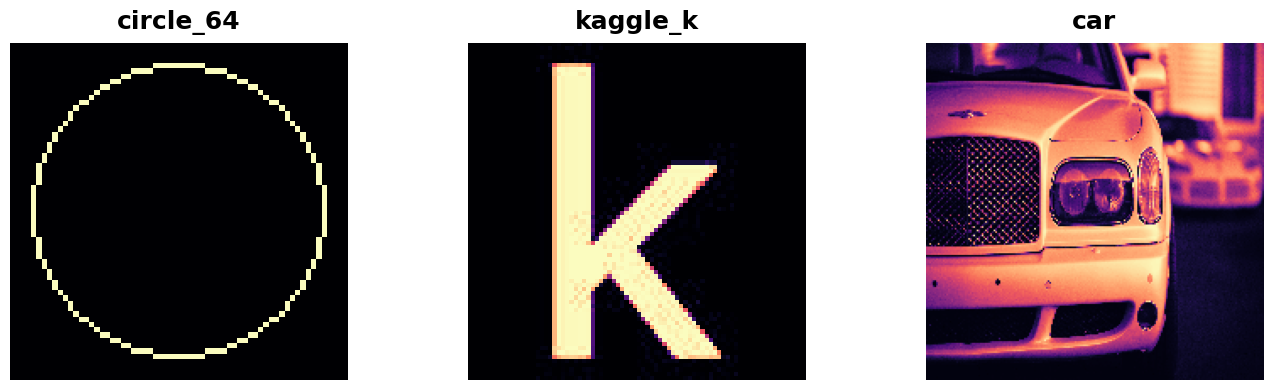

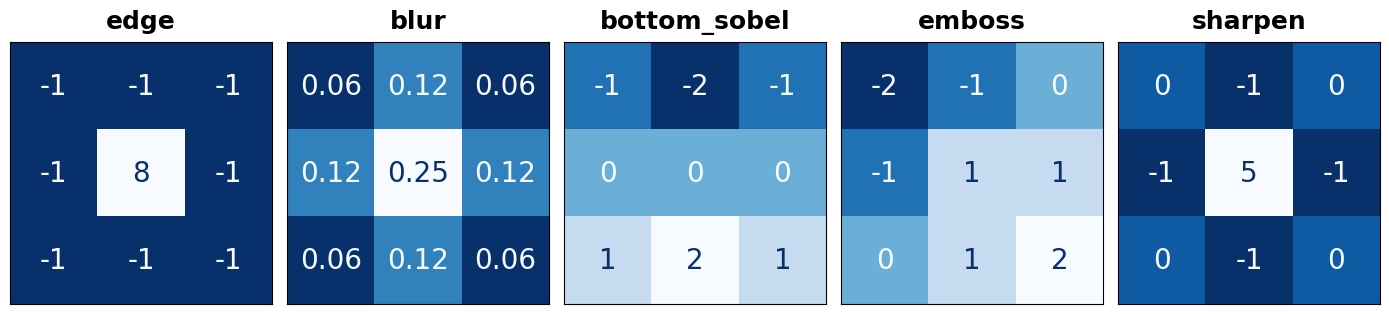

In [3]:
image_dir = '../resources/computer-vision-resources/'
circle_64 = tf.expand_dims(circle([64, 64], val=1.0, r_shrink=4), axis=-1)
kaggle_k = read_image(image_dir + str('k.jpg'), channels=1)
car = read_image(image_dir + str('car_illus.jpg'), channels=1)
car = tf.image.resize(car, size=[200, 200])
images = [(circle_64, "circle_64"), (kaggle_k, "kaggle_k"), (car, "car")]

plt.figure(figsize=(14, 4))
for i, (img, title) in enumerate(images):
    plt.subplot(1, len(images), i+1)
    plt.imshow(tf.squeeze(img))
    plt.axis('off')
    plt.title(title)
plt.show();

kernels = [(edge, "edge"), (blur, "blur"), (bottom_sobel, "bottom_sobel"),
           (emboss, "emboss"), (sharpen, "sharpen")]
plt.figure(figsize=(14, 4))
for i, (krn, title) in enumerate(kernels):
    plt.subplot(1, len(kernels), i+1)
    show_kernel(krn, digits=2, text_size=20)
    plt.title(title)
plt.show()

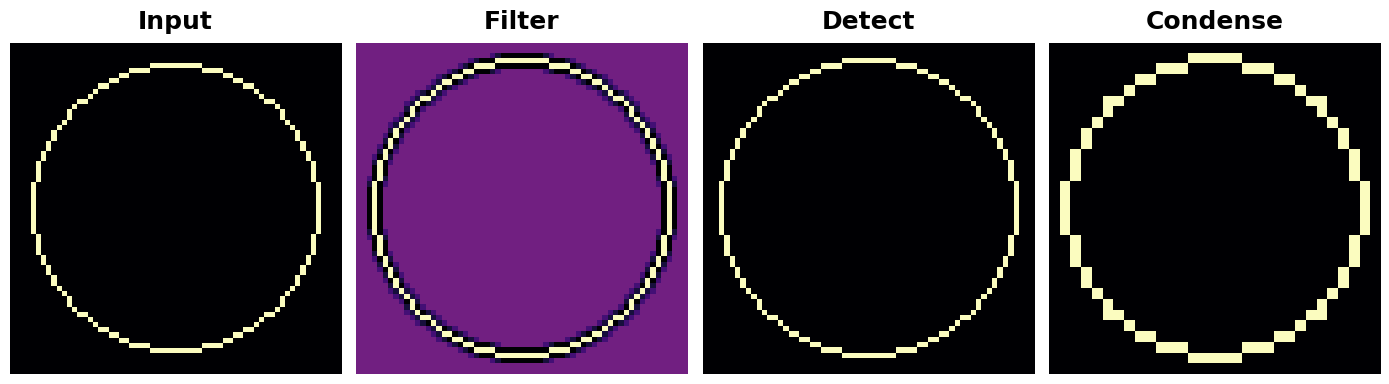

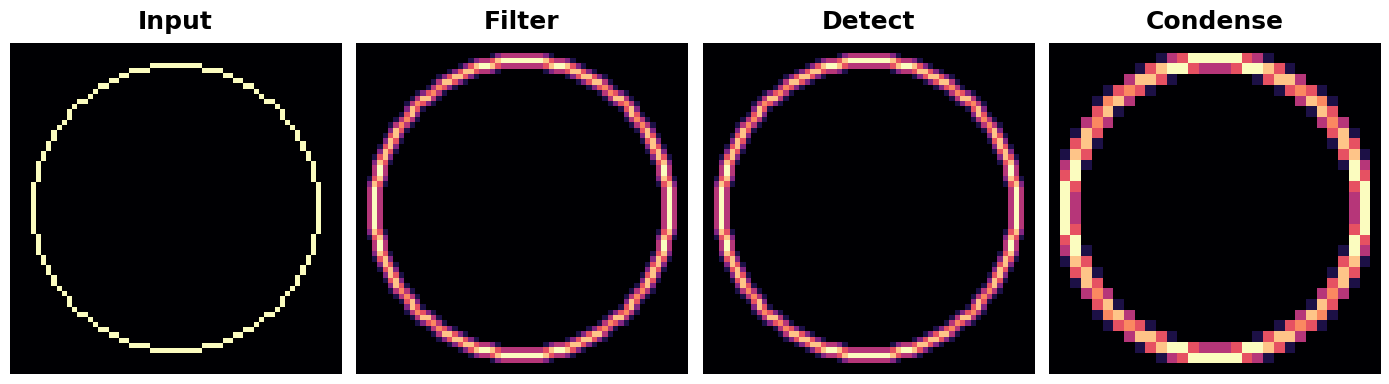

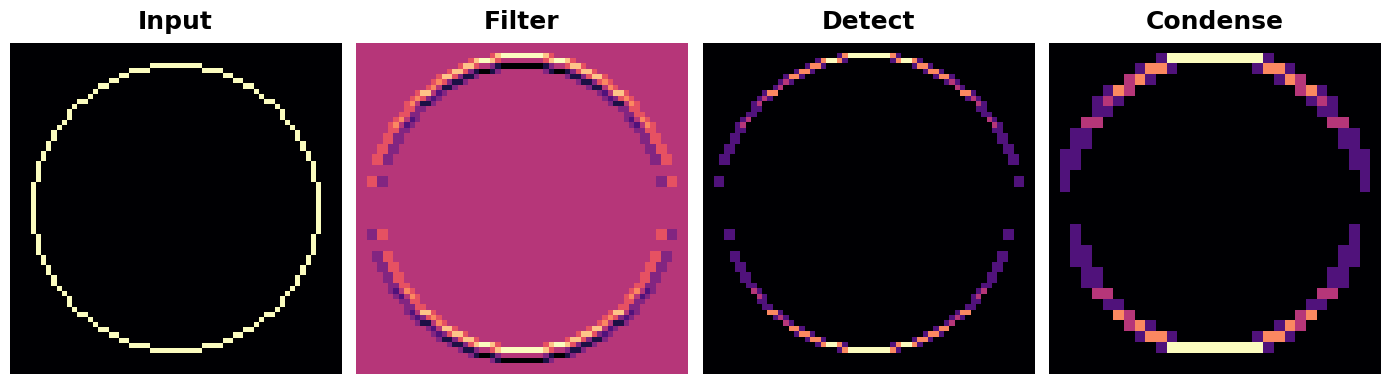

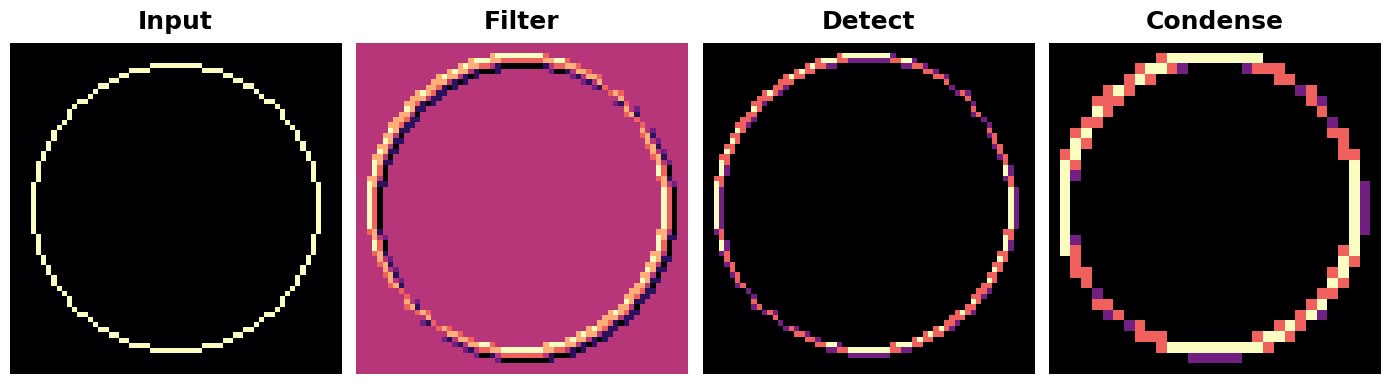

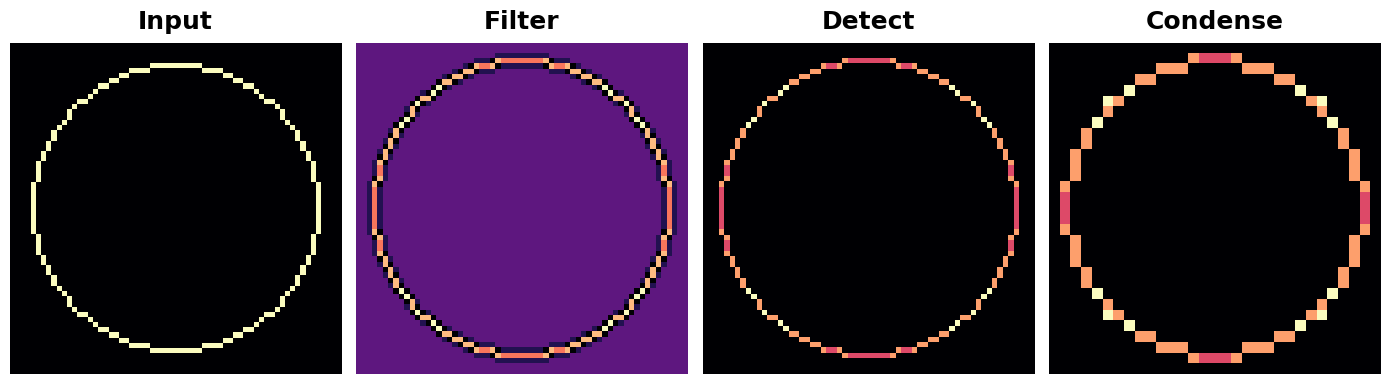

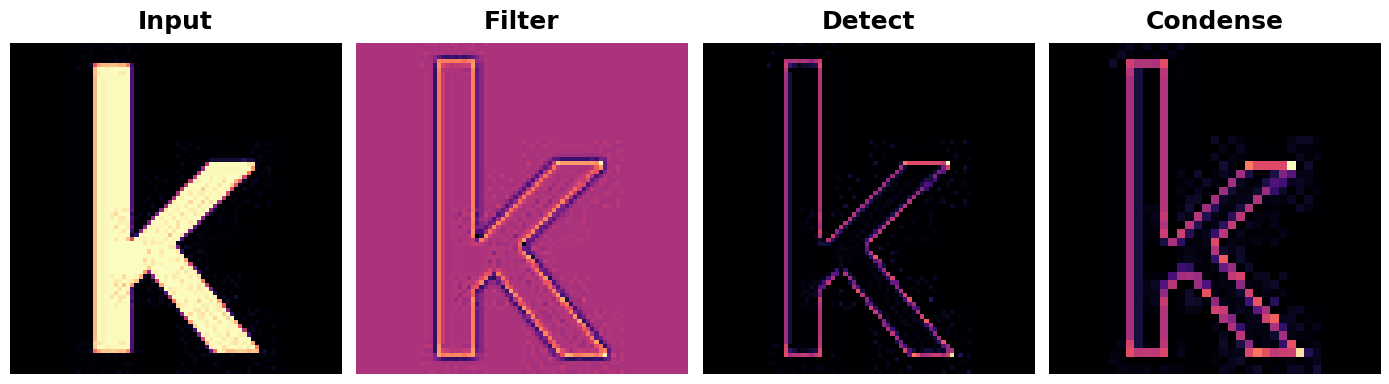

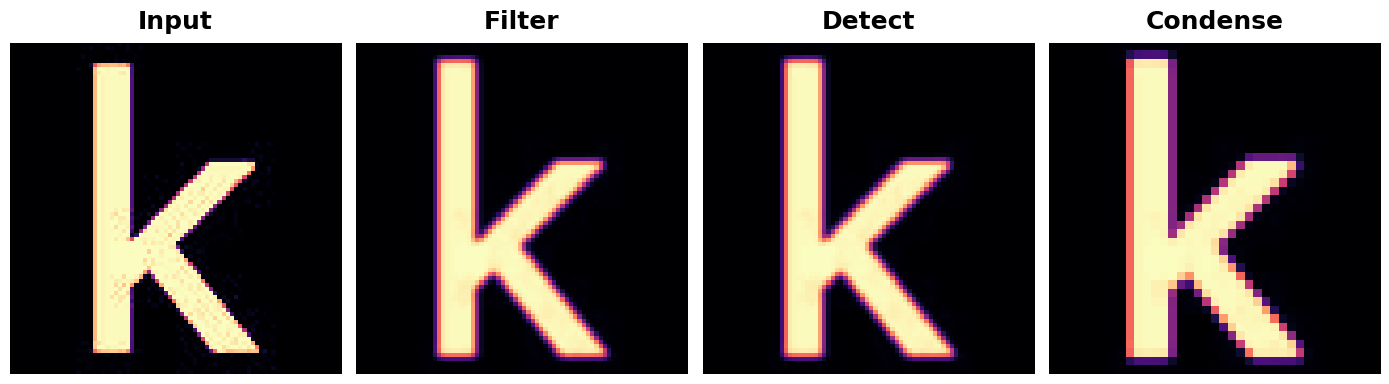

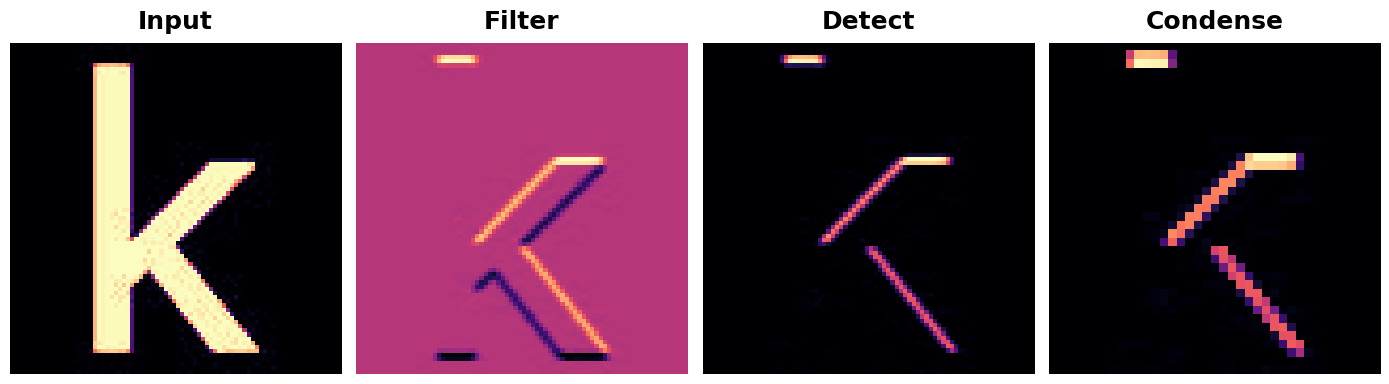

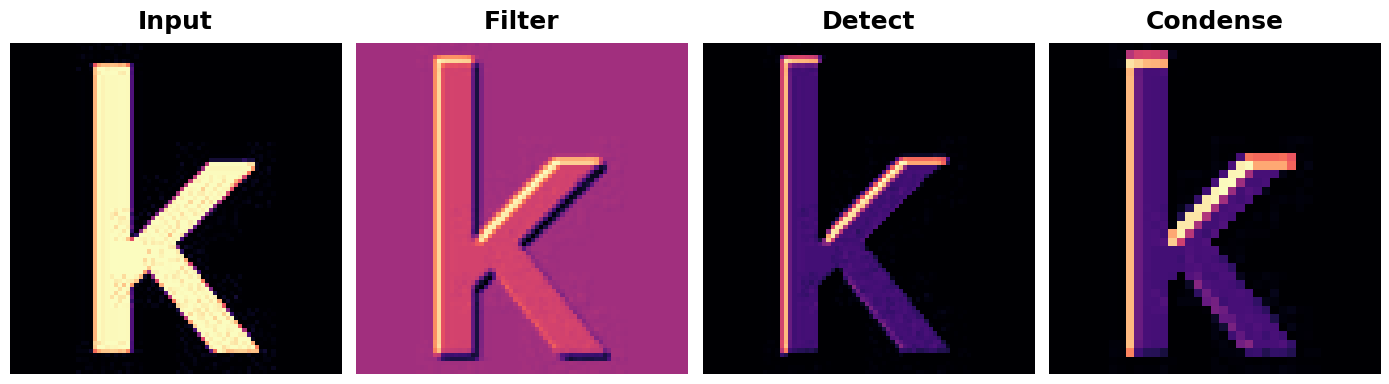

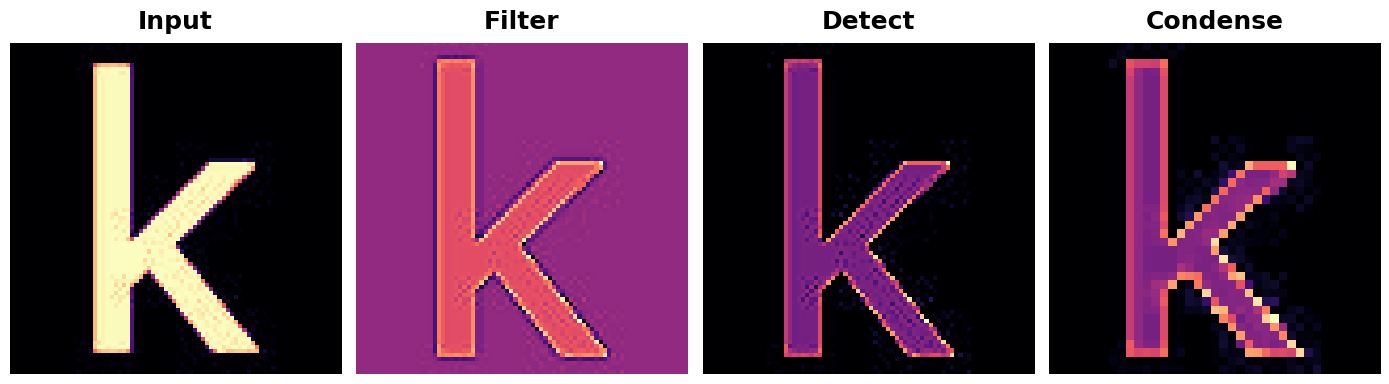

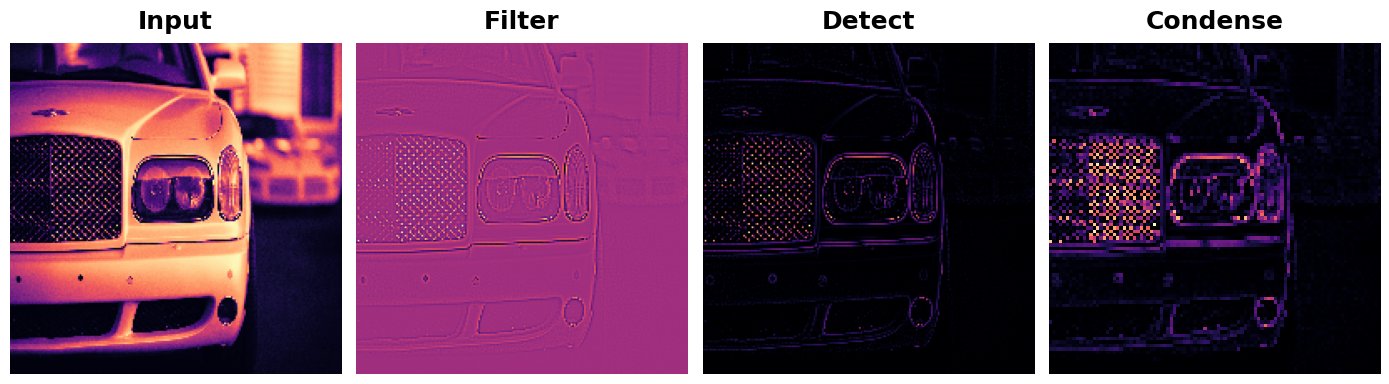

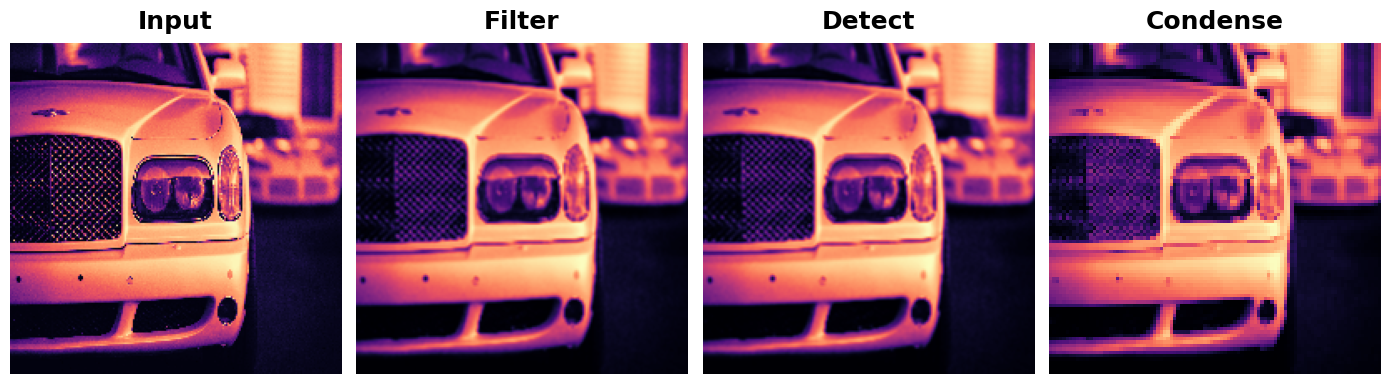

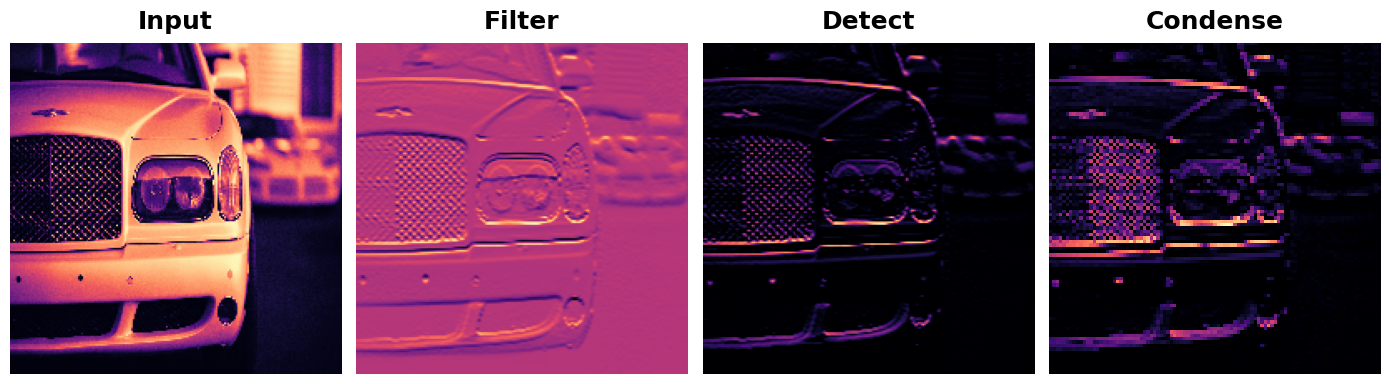

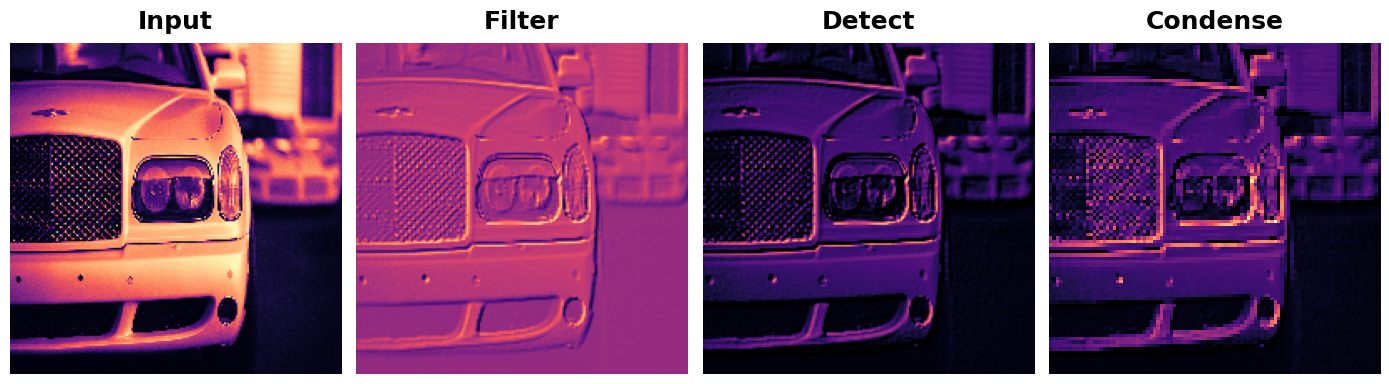

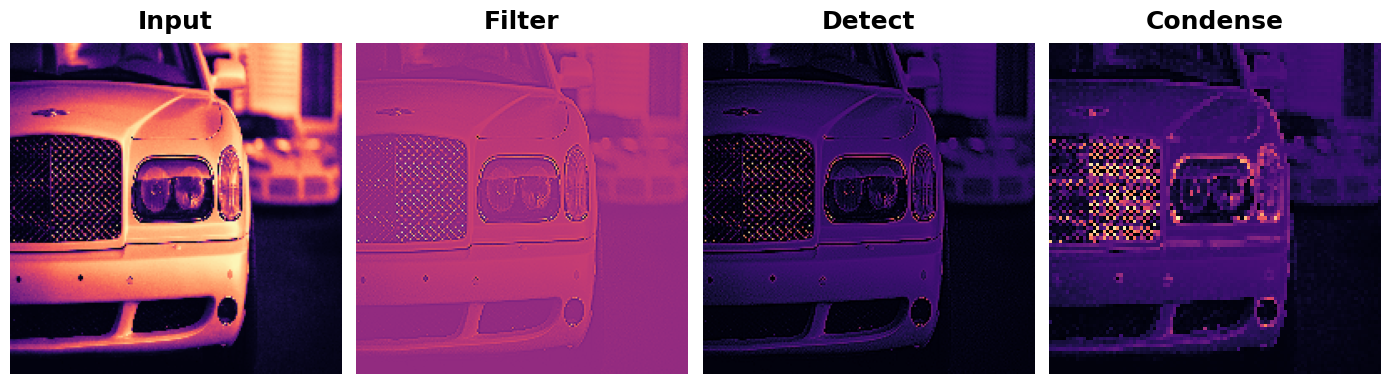

In [4]:
images = [circle_64, kaggle_k, car]
kernels = [edge, blur, bottom_sobel, emboss, sharpen]

for pair in [(i, k) for i in images for k in kernels]:
    # choose an image
    image = pair[0]
    
    # choose a kernel
    kernel = pair[1]
    
    show_extraction(
        image, kernel,
    
        # YOUR CODE HERE: set parameters
        conv_stride=1,
        conv_padding='valid',
        pool_size=2,
        pool_stride=2,
        pool_padding='same',
        
        subplot_shape=(1, 4),
        figsize=(14, 6),
    )

In [5]:
from IPython.display import display, Markdown

content = f"""
**Q**: **If the first layer is a convolution with 3x3 kernels, then each neuron in that layer gets input 
from a  patch of pixels (except maybe at the border). If you add another convolutional layer with 3x3 kernels,
each neuron in the patch in the middle layer is connected to a 3x3 input patch, but they overlap in a 5x5 patch, 
so that neuron at top has a 5x5 receptive field. If you added a third convolutional layer with a 3x3 kernel, 
what receptive field would its neurons have?**<br>
**A**: The third layer would have a 7x7 receptive field.

So why stack layers like this? Three (3, 3) kernels have 27 parameters, while one (7, 7) kernel has 49, 
though they both create the same receptive field. This stacking-layers trick is one of the ways convnets 
are able to create large receptive fields without increasing the number of parameters too much.
"""

display(Markdown(content))


**Q**: **If the first layer is a convolution with 3x3 kernels, then each neuron in that layer gets input 
from a  patch of pixels (except maybe at the border). If you add another convolutional layer with 3x3 kernels,
each neuron in the patch in the middle layer is connected to a 3x3 input patch, but they overlap in a 5x5 patch, 
so that neuron at top has a 5x5 receptive field. If you added a third convolutional layer with a 3x3 kernel, 
what receptive field would its neurons have?**<br>
**A**: The third layer would have a 7x7 receptive field.

So why stack layers like this? Three (3, 3) kernels have 27 parameters, while one (7, 7) kernel has 49, 
though they both create the same receptive field. This stacking-layers trick is one of the ways convnets 
are able to create large receptive fields without increasing the number of parameters too much.


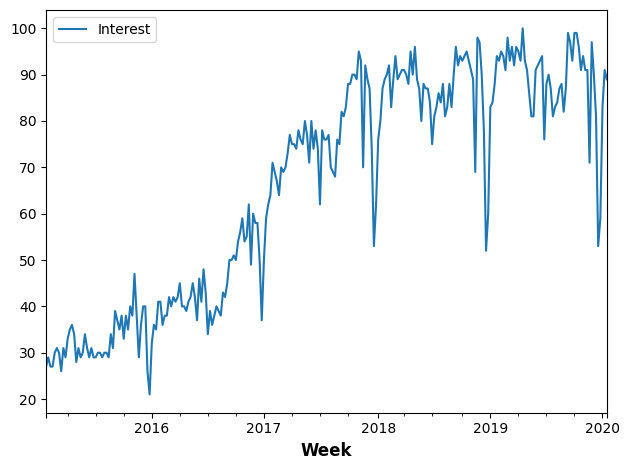

In [6]:
import pandas as pd

# Load the time series as a Pandas dataframe
machinelearning = pd.read_csv(
    '../resources/computer-vision-resources/machinelearning.csv',
    parse_dates=['Week'],
    index_col='Week',
)

machinelearning.plot();

In [7]:
content = f"""
Convolutional networks turn out to be useful not only (two-dimensional) images, but also on things 
like time-series (one-dimensional) or videos (three-dimensional).

What about the kernels? Images are two-dimensional and so our kernels were 2D arrays. A time-series 
is one-dimensional, so what should the kernel be? A 1D array! Here are some kernels sometimes used on 
time-series data:
"""

display(Markdown(content))


Convolutional networks turn out to be useful not only (two-dimensional) images, but also on things 
like time-series (one-dimensional) or videos (three-dimensional).

What about the kernels? Images are two-dimensional and so our kernels were 2D arrays. A time-series 
is one-dimensional, so what should the kernel be? A 1D array! Here are some kernels sometimes used on 
time-series data:


In [8]:
detrend = tf.constant([-1, 1], dtype=tf.float32)
average = tf.constant([0.2, 0.2, 0.2, 0.2, 0.2], dtype=tf.float32)
spencer = tf.constant([-3, -6, -5, 3, 21, 46, 67, 74, 67, 46, 32, 3, -5, -6, -3], dtype=tf.float32) / 320

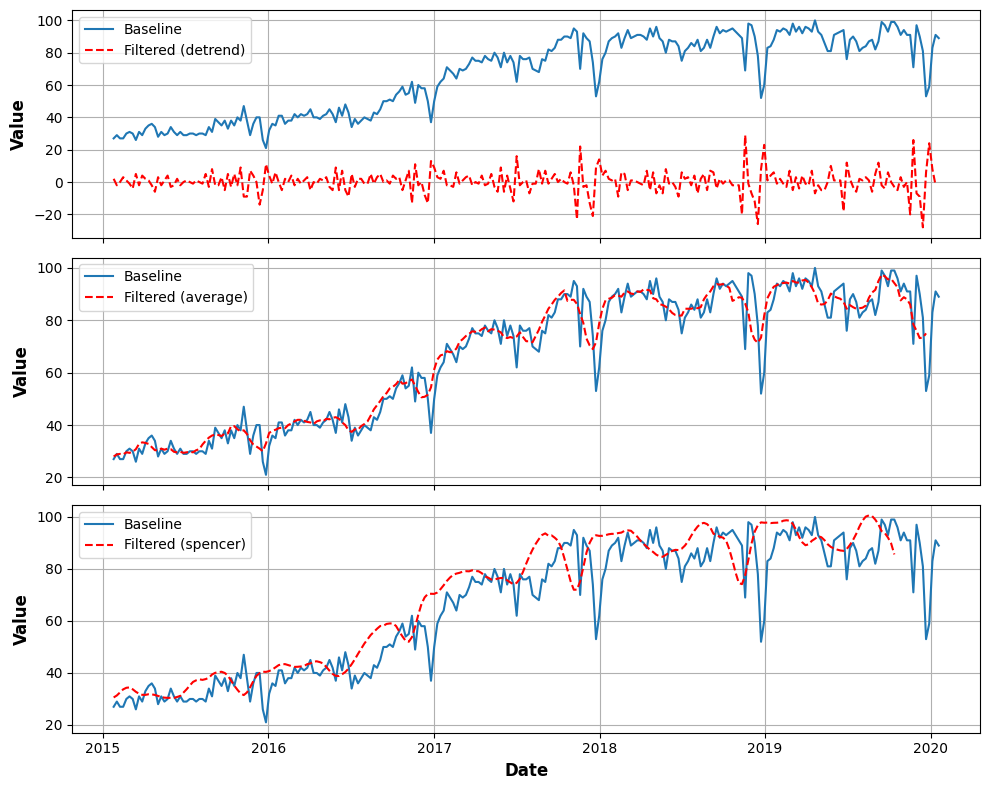

In [9]:
kernels = {
    'detrend': detrend,
    'average': average,
    'spencer': spencer
}

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 8), sharex=True)
for i, (name, kernel) in enumerate(kernels.items()):
    # Reformat for TensorFlow
    ts_data = machinelearning.to_numpy()
    ts_data = tf.expand_dims(ts_data, axis=0)
    ts_data = tf.cast(ts_data, dtype=tf.float32)
    kern = tf.reshape(kernel, shape=(*kernel.shape, 1, 1))
    
    # Apply convolution
    ts_filter = tf.nn.conv1d(
        input=ts_data,
        filters=kern,
        stride=1,
        padding='VALID',
    )
    
    # Format as Pandas Series
    machinelearning_filtered = pd.Series(tf.squeeze(ts_filter).numpy(), 
                                         index=machinelearning.index[:len(ts_filter.numpy()[0])])
    

    axes[i].plot(machinelearning.index, machinelearning, label='Baseline')
    axes[i].plot(machinelearning_filtered.index, machinelearning_filtered, 
                 label=f'Filtered ({name})', color='r', linestyle='dashed')
    axes[i].set_ylabel('Value')
    axes[i].legend()
    axes[i].grid()

# Set common x-label
axes[-1].set_xlabel('Date')
plt.tight_layout()
plt.show()


In [10]:
content = f"""
The detrend kernel filters for changes in the series, while average and spencer are both 
"smoothers" that filter for low-frequency components in the series.

To predict the future popularity of search terms, one might train a convnet on time-series 
like this one. It would try to learn what features in those series are most informative 
for the prediction.
"""
display(Markdown(content))


The detrend kernel filters for changes in the series, while average and spencer are both 
"smoothers" that filter for low-frequency components in the series.

To predict the future popularity of search terms, one might train a convnet on time-series 
like this one. It would try to learn what features in those series are most informative 
for the prediction.
